In [1]:
print('In the name of Allah')

In the name of Allah


# Module 8: Scaling — Practice Problems

এই notebook-এ real datasets ব্যবহার করে scaling-এর সব concepts practice করা হবে।

**Datasets used:**
- California Housing Dataset
- Diabetes Dataset
- Breast Cancer Dataset
- Wine Dataset

সব dataset sklearn থেকে directly load করা যাবে — কোনো external file লাগবে না।

---
## Setup — Run this first

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing, load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer

print('Setup complete!')

Setup complete!


---
# Part 1: Why Scaling Matters
**Dataset: California Housing**

### Problem 1
California Housing dataset load করো এবং একটি DataFrame বানাও।
প্রতিটি feature-এর min, max এবং mean print করো।
দেখো feature-গুলোর range কতটা আলাদা।

In [3]:
# Load dataset
housing = fetch_california_housing()
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)

# Your code here: print min, max, mean of each feature

print(f'Min : {df_housing.min()}')

print(f'Max : {df_housing.max()}')

print(f'Mean : {df_housing.mean()}')


Min : MedInc          0.499900
HouseAge        1.000000
AveRooms        0.846154
AveBedrms       0.333333
Population      3.000000
AveOccup        0.692308
Latitude       32.540000
Longitude    -124.350000
dtype: float64
Max : MedInc           15.000100
HouseAge         52.000000
AveRooms        141.909091
AveBedrms        34.066667
Population    35682.000000
AveOccup       1243.333333
Latitude         41.950000
Longitude      -114.310000
dtype: float64
Mean : MedInc           3.870671
HouseAge        28.639486
AveRooms         5.429000
AveBedrms        1.096675
Population    1425.476744
AveOccup         3.070655
Latitude        35.631861
Longitude     -119.569704
dtype: float64


### Problem 2
California Housing dataset-এর সব features-এর distribution একসাথে plot করো (histogram)।
কোন features-এর range সবচেয়ে বড়? কোনটা সবচেয়ে ছোট? চিহ্নিত করো।

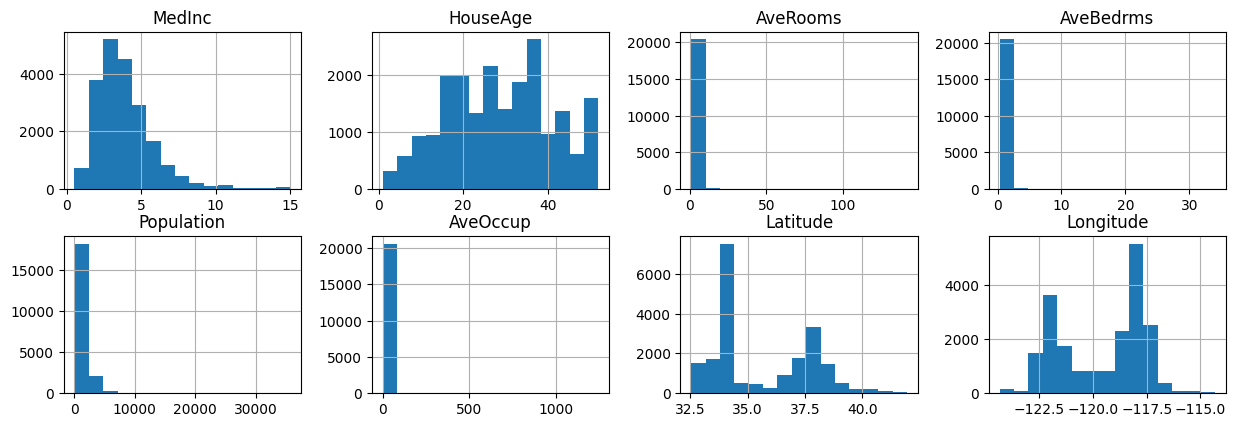

In [4]:
# Your code here: plot histogram for all features
df_housing.hist(bins=15, figsize=(15, 10), layout=(4, 4))
plt.show()

In [5]:
feature_range = df_housing.max() - df_housing.min()
print(feature_range)

largest_range_feature = feature_range.idxmax()
smallest_range_feature = feature_range.idxmin()


print(f'Feature with Largest range : {largest_range_feature}')
print(f'Feature with Smallest range : {smallest_range_feature}')

print("\nLargest range value:", feature_range.max())
print("Smallest range value:", feature_range.min())

MedInc           14.500200
HouseAge         51.000000
AveRooms        141.062937
AveBedrms        33.733333
Population    35679.000000
AveOccup       1242.641026
Latitude          9.410000
Longitude        10.040000
dtype: float64
Feature with Largest range : Population
Feature with Smallest range : Latitude

Largest range value: 35679.0
Smallest range value: 9.410000000000004


### Problem 3
Diabetes dataset load করো। Features-এর scale দেখে বলো —
scaling ছাড়া কোন ধরনের ML model সবচেয়ে বেশি সমস্যায় পড়বে এবং কেন?
(KNN, Decision Tree — এই তিনটির মধ্যে তুলনা করো।)

In [6]:
# Load diabetes dataset
diabetes = load_diabetes()
df_diabetes = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Your code here: explore and answer
print(df_diabetes.head())
print(df_diabetes.describe())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164

<Axes: >

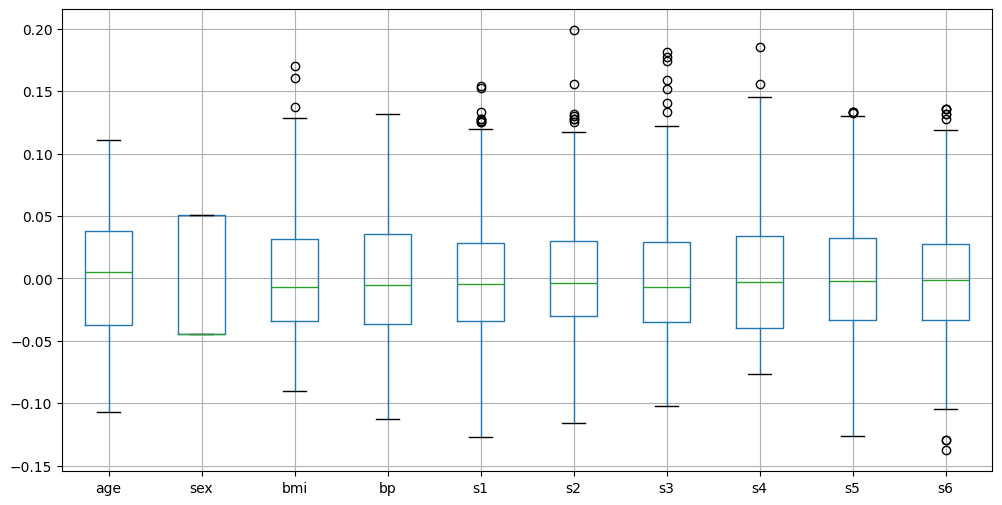

In [7]:
df_diabetes.boxplot(figsize=(12,6))

Without feature scaling, KNN is affected the most because it depends on distance calculation. If features are on different scales, large-valued features dominate the distance and produce incorrect predictions.

Decision Tree is not affected by feature scaling because it splits data based on feature thresholds, not on distance or magnitude.

Therefore, among KNN and Decision Tree, KNN is highly sensitive to scaling, while Decision Tree is scale-independent.

---
# Part 2: Standard Scaling
**Dataset: Breast Cancer**

### Problem 4
Breast Cancer dataset load করো এবং train-test split করো (test_size=0.2, random_state=42)।
এরপর StandardScaler দিয়ে শুধু training data-তে fit করো এবং দুটোতেই transform করো।

In [8]:
# Load dataset
cancer = load_breast_cancer()
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target

# Your code here: train-test split, fit StandardScaler on train, transform both
X = df_cancer
y = y_cancer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

ss = StandardScaler()

ss.fit(X_train)

X_train = ss.transform(X_train)
X_test = ss.transform(X_test)

In [9]:
X_train
display(X_test)

array([[-0.46649743, -0.13728933, -0.44421138, ..., -0.19435087,
         0.17275669,  0.20372995],
       [ 1.36536344,  0.49866473,  1.30551088, ...,  0.99177862,
        -0.561211  , -1.00838949],
       [ 0.38006578,  0.06921974,  0.40410139, ...,  0.57035018,
        -0.10783139, -0.20629287],
       ...,
       [-0.73547237, -0.99852603, -0.74138839, ..., -0.27741059,
        -0.3820785 , -0.32408328],
       [ 0.02898271,  2.0334026 ,  0.0274851 , ..., -0.49027026,
        -1.60905688, -0.33137507],
       [ 1.87216885,  2.80077153,  1.80354992, ...,  0.7925579 ,
        -0.05868885, -0.09467243]])

### Problem 5
Problem 4-এর scaled training data-র mean এবং standard deviation print করো।
Expected output: mean ≈ 0, std ≈ 1।
যদি এই output না পাও, কোথায় ভুল হয়েছে খুঁজে বের করো।

In [10]:
# Your code here: verify mean and std after scaling

print(f'Mean : {round(X_train.mean(), 5)}')
print(f'Std : {round(X_train.std(), 5)}')

Mean : -0.0
Std : 1.0


### Problem 6
Breast Cancer dataset-এর যেকোনো একটি feature নিয়ে scaling-এর আগে এবং পরে
KDE plot পাশাপাশি (subplot) দেখাও।
Shape কি একই থাকে নাকি বদলে যায়?

In [11]:
# Your code here: before vs after KDE plot side by side

cancer = load_breast_cancer()
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target

# Your code here: train-test split, fit StandardScaler on train, transform both
X = df_cancer
y = y_cancer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Copy original data before scaling for plotting
X_train_before = X_train.copy()

# sns.kdeplot( data = X_train_before, x = 'mean radius')

ss = StandardScaler()

ss.fit(X_train)

X_train_scaled = ss.transform(X_train)
X_test_scaled = ss.transform(X_test)

X_train_after = pd.DataFrame(X_train_scaled, columns=X_train.columns)


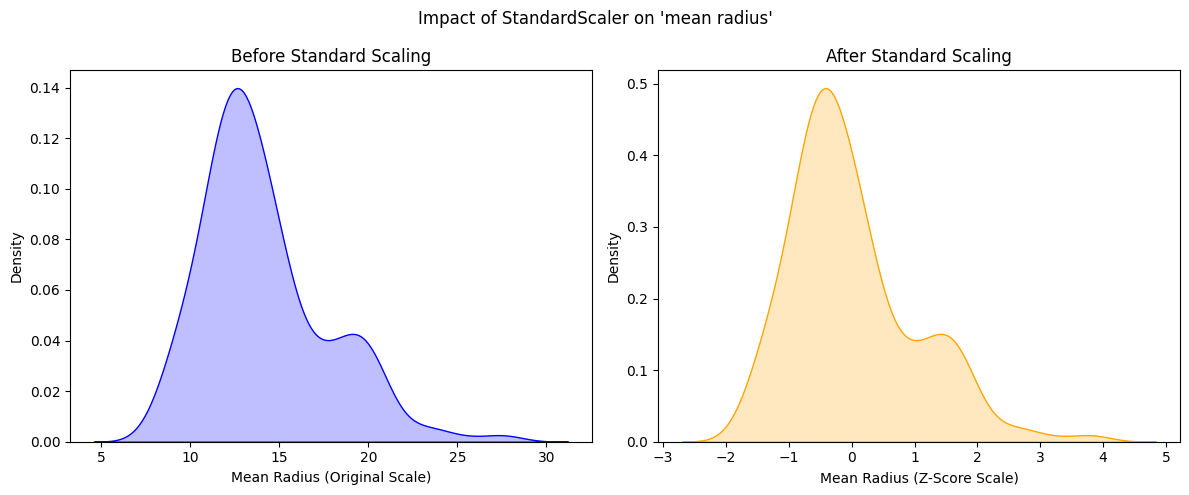

In [12]:
# 1. Create a figure with 1 row and 2 columns of subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 2. Plot "Before Scaling" on the first axis (ax1)
sns.kdeplot(data=X_train_before, x="mean radius", ax=ax1, fill=True, color="blue")
ax1.set_title("Before Standard Scaling")
ax1.set_xlabel("Mean Radius (Original Scale)")

# 3. Plot "After Scaling" on the second axis (ax2)
sns.kdeplot(data=X_train_after, x="mean radius", ax=ax2, fill=True, color="orange")
ax2.set_title("After Standard Scaling")
ax2.set_xlabel("Mean Radius (Z-Score Scale)")

# Add an overarching main title
plt.suptitle("Impact of StandardScaler on 'mean radius'")

# Adjust layout and display
plt.tight_layout()
plt.show()

### Problem 7
StandardScaler manually implement করো — sklearn ব্যবহার না করে।
formula: z = (x - mean) / std
Diabetes dataset-এর 'bmi' column-এ apply করো এবং sklearn-এর output-এর সাথে মিলিয়ে দেখো।

In [13]:
# Your code here: manual StandardScaler and compare with sklearn

# df_diabetes.info()

mean_bmi = df_diabetes['bmi'].mean()
std_bmi = df_diabetes['bmi'].std()

z = ( df_diabetes['bmi'] - mean_bmi ) / std_bmi

ss = StandardScaler()

ss.fit(df_diabetes[['bmi']])

bmi_sklearn_scaled = ss.transform(df_diabetes[['bmi']]).ravel()


In [14]:
print("Manual mean:", z.mean())
print("Sklearn mean:", bmi_sklearn_scaled.mean())

print("Manual std:", z.std())
print("Sklearn std:", bmi_sklearn_scaled.std())

# Check if identical
print(np.allclose(z, bmi_sklearn_scaled))

Manual mean: -4.822688251765386e-17
Sklearn mean: -2.813234813529808e-17
Manual std: 0.9999999999999993
Sklearn std: 1.0
False


---
# Part 3: MinMax Scaling
**Dataset: Wine**

### Problem 8
Wine dataset load করো। MinMaxScaler apply করো সব features-এ।
Scaled data-র min এবং max verify করো — সব feature-এ min=0 এবং max=1 হওয়া উচিত।

In [15]:
# Load dataset
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)

df_wine.info()

# Your code here: apply MinMaxScaler and verify min/max
mms = MinMaxScaler()

mms.fit(df_wine)

df_wine = mms.transform(df_wine)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

In [16]:
df_wine = pd.DataFrame(df_wine)

df_wine.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,0.518584,0.315484,0.538244,0.458502,0.323278,0.453487,0.356386,0.437460,0.372523,0.322363,0.388170,0.491460,0.334446
std,0.213639,0.220780,0.146708,0.172142,0.155244,0.215811,0.210730,0.234818,0.180555,0.197806,0.185831,0.260070,0.224613
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.350658,0.170455,0.454545,0.340206,0.195652,0.262931,0.182489,0.264151,0.264984,0.165529,0.245935,0.244505,0.158702
50%,0.531579,0.222332,0.534759,0.458763,0.304348,0.474138,0.378692,0.396226,0.361199,0.290956,0.394309,0.553114,0.282097
75%,0.696711,0.462945,0.640374,0.561856,0.402174,0.627586,0.534810,0.580189,0.485804,0.419795,0.520325,0.695971,0.504280
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Problem 9
MinMaxScaler manually implement করো — sklearn ব্যবহার না করে।
formula: x_scaled = (x - min) / (max - min)
Wine dataset-এর 'alcohol' column-এ apply করো এবং sklearn output-এর সাথে তুলনা করো।

In [17]:
# Your code here: manual MinMaxScaler and compare with sklearn

# Load dataset
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)

min_alcohol = df_wine['alcohol'].min()
max_alcohol = df_wine['alcohol'].max()

x_scaled = ( df_wine['alcohol'] - min_alcohol ) / ( max_alcohol - min_alcohol )

mms = MinMaxScaler()
mms.fit(df_wine[['alcohol']])

alcohol_sklearn = mms.transform(df_wine[['alcohol']]).ravel()


In [18]:
print("Manual Min:", x_scaled.min())
print("Manual Max:", x_scaled.max())

print("Sklearn Min:", alcohol_sklearn.min())
print("Sklearn Max:", alcohol_sklearn.max())

print("\nMatch:", np.allclose(x_scaled, alcohol_sklearn))

Manual Min: 0.0
Manual Max: 1.0
Sklearn Min: 0.0
Sklearn Max: 1.0

Match: True


### Problem 10
Wine dataset-এ একটি artificial outlier যোগ করো (যেমন: alcohol = 500)।
MinMaxScaler apply করার পর দেখো বাকি সব values কীভাবে প্রভাবিত হয়।
Before এবং after plot করো।

In [19]:
# Your code here: add outlier, apply MinMaxScaler, plot before vs after

outlier = 500
df_wine.loc[df_wine.index.max() + 1, "alcohol"] = outlier

alcohol_before = df_wine[["alcohol"]].copy()

mms = MinMaxScaler()

mms.fit(df_wine[['alcohol']])

df_wine['alcohol'] = mms.transform(df_wine[['alcohol']])

alcohol_after = pd.DataFrame(
    mms.transform(alcohol_before), columns=["alcohol_scaled"]
)

df_wine["alcohol"] = alcohol_after["alcohol_scaled"].values


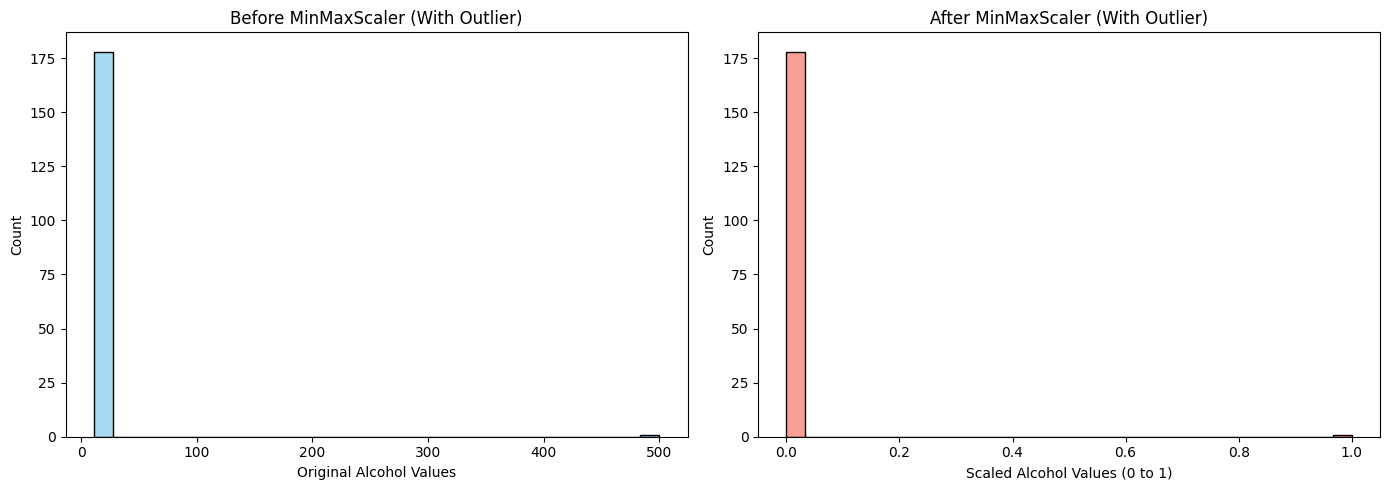

In [20]:
# 5. Plot Before vs After using Seaborn
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Before Scaling (Correct Seaborn syntax using 'x' as a column string)
sns.histplot(data=alcohol_before, x="alcohol", bins=30, color="skyblue", ax=ax1)
ax1.set_title("Before MinMaxScaler (With Outlier)")
ax1.set_xlabel("Original Alcohol Values")

# Plot After Scaling
sns.histplot(
    data=alcohol_after, x="alcohol_scaled", bins=30, color="salmon", ax=ax2
)
ax2.set_title("After MinMaxScaler (With Outlier)")
ax2.set_xlabel("Scaled Alcohol Values (0 to 1)")

plt.tight_layout()
plt.show()

### Problem 11
একই outlier-যুক্ত Wine data-তে এবার StandardScaler apply করো।
MinMaxScaler vs StandardScaler — কোনটা outlier-এ বেশি ক্ষতিগ্রস্ত হয়েছে?
দুটির output plot করে তুলনা করো।

In [21]:
# Your code here: compare MinMaxScaler vs StandardScaler with outlier present

wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)

outlier = 500
df_wine.loc[df_wine.index.max() + 1, "alcohol"] = outlier


mms = MinMaxScaler()

alcohol_mms = pd.DataFrame(
    mms.fit_transform(alcohol_before), columns=["alcohol_mms"]
)

ss = StandardScaler()

ss = StandardScaler()
alcohol_ss = pd.DataFrame(
    ss.fit_transform(alcohol_before), columns=["alcohol_ss"]
)

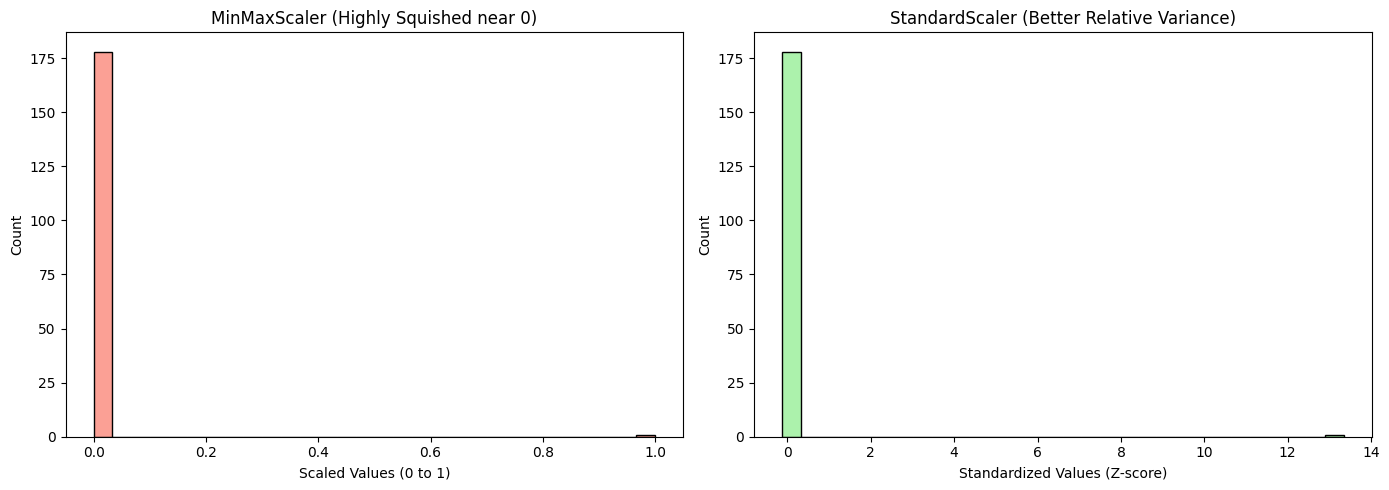

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# MinMaxScaler Plot

sns.histplot(data=alcohol_mms, x="alcohol_mms", bins=30, color="salmon", ax=ax1)
ax1.set_title("MinMaxScaler (Highly Squished near 0)")
ax1.set_xlabel("Scaled Values (0 to 1)")

# StandardScaler Plot

sns.histplot(data=alcohol_ss, x="alcohol_ss", bins=30, color="lightgreen", ax=ax2)
ax2.set_title("StandardScaler (Better Relative Variance)")
ax2.set_xlabel("Standardized Values (Z-score)")

plt.tight_layout()
plt.show()

---
# Part 4: Robust Scaler
**Dataset: California Housing**

### Problem 12
California Housing dataset-এ 'AveRooms' column-এ RobustScaler apply করো।
Scaled data-র median এবং IQR print করো।
Expected: median ≈ 0।

<Axes: xlabel='AveRooms', ylabel='Density'>

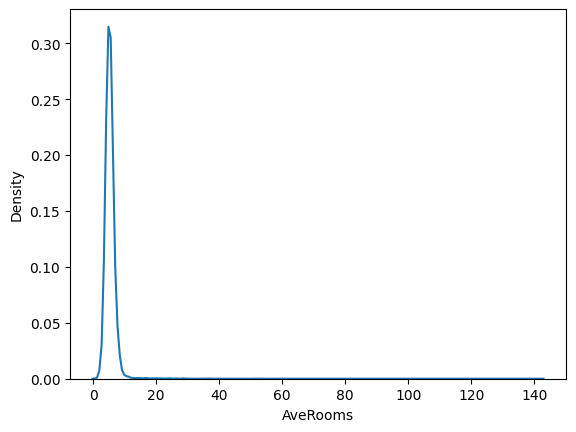

In [23]:
# Your code here: RobustScaler on AveRooms, check median and IQR

housing = fetch_california_housing(as_frame=True)
df = housing.frame

df

sns.kdeplot(data = df, x = df['AveRooms'])


In [24]:
rs = RobustScaler()

rs.fit(df[['AveRooms']])

df['AveRooms'] = rs.transform(df[['AveRooms']]).ravel()

<Axes: xlabel='AveRooms', ylabel='Density'>

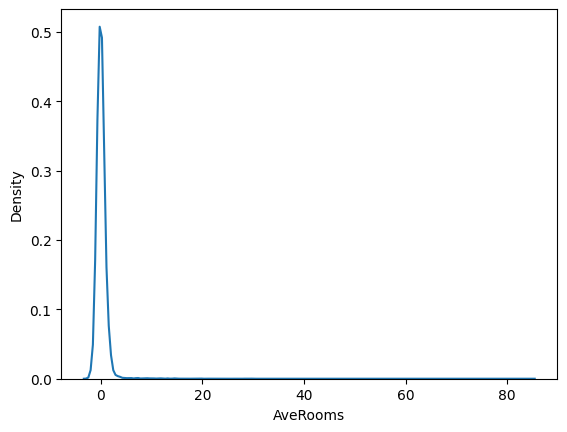

In [25]:
sns.kdeplot(data = df, x = df['AveRooms'])

In [26]:
median = df['AveRooms'].median()

print(f'Median : {median}')

Q1 = df['AveRooms'].quantile(0.25)

Q3 = df['AveRooms'].quantile(0.75)

IQR = Q3 - Q1

print(f'IQR : {round(IQR, 5)}')

Median : 0.0
IQR : 1.0


### Problem 13
RobustScaler manually implement করো।
formula: x_scaled = (x - median) / IQR
California Housing-এর 'AveOccup' column-এ apply করো এবং sklearn output-এর সাথে মিলিয়ে দেখো।

In [27]:
# Your code here: manual RobustScaler and compare with sklearn

median = df['AveOccup'].median()

Q1 = df['AveOccup'].quantile(0.25)

Q3 = df['AveOccup'].quantile(0.75)

IQR = Q3 - Q1

x_scaled = ( df['AveOccup'] - median ) / IQR

In [28]:
rs = RobustScaler()

rs.fit(df[['AveOccup']])

occup_sklearn = rs.transform(df[['AveOccup']]).ravel()

print("Manual Median:", np.median(x_scaled))
print("Sklearn Median:", np.median(occup_sklearn))

print("\nMatch:", np.allclose(x_scaled, occup_sklearn))

Manual Median: 0.0
Sklearn Median: 0.0

Match: True


### Problem 14
California Housing-এর 'AveRooms' column-এ তিনটি scaler একসাথে compare করো:
StandardScaler, MinMaxScaler, RobustScaler।
তিনটির output এর KDE plot পাশাপাশি (3 subplots) দেখাও।
কোনটা outlier-এ সবচেয়ে কম প্রভাবিত হয়েছে?

In [29]:
# Your code here: compare all 3 scalers side by side with KDE plots

# Standard Scaler

ss = StandardScaler()

ss.fit(df[['AveRooms']])

scaler = ss.transform(df[['AveRooms']]).ravel()

# MinMax Scaler

mms = MinMaxScaler()

mms.fit(df[['AveRooms']])

minmax = mms.transform(df[['AveRooms']]).ravel()

# Robust Scaler

rs = RobustScaler()

rs.fit(df[['AveRooms']])

robust = rs.transform(df[['AveRooms']]).ravel()


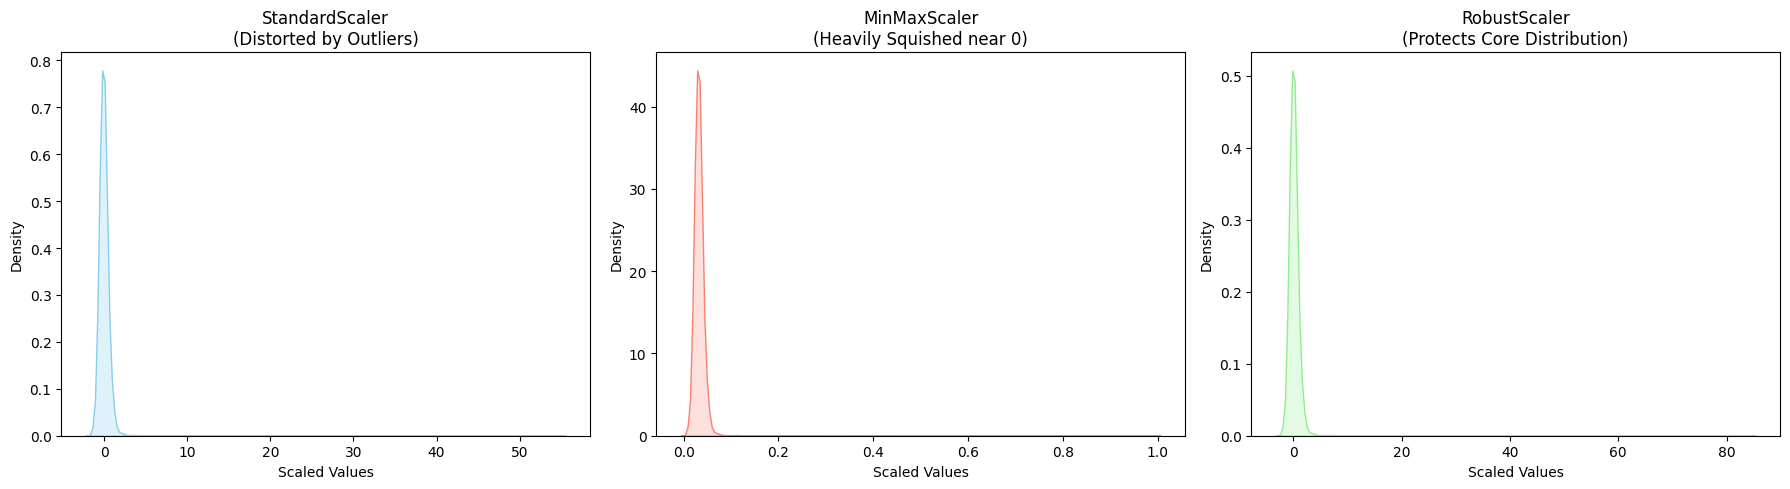

In [30]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Plot StandardScaler output

sns.kdeplot(scaler, fill=True, color="skyblue", ax=ax1)
ax1.set_title("StandardScaler\n(Distorted by Outliers)")
ax1.set_xlabel("Scaled Values")

# Plot MinMaxScaler output
sns.kdeplot(minmax, fill=True, color="salmon", ax=ax2)
ax2.set_title("MinMaxScaler\n(Heavily Squished near 0)")
ax2.set_xlabel("Scaled Values")

# Plot RobustScaler output
sns.kdeplot(robust, fill=True, color="lightgreen", ax=ax3)
ax3.set_title("RobustScaler\n(Protects Core Distribution)")
ax3.set_xlabel("Scaled Values")

# Adjust spacing and display
plt.tight_layout()
plt.show()

### Problem 15
Data leakage experiment করো:
- Case A: Scaler শুধু train data-তে fit করো, test-এ transform করো।
- Case B: Scaler পুরো dataset-এ fit করো, তারপর split করো।

Diabetes dataset ব্যবহার করো। দুই case-এ test set-এর mean এবং std print করো।
পার্থক্য দেখাও এবং কোনটা সঠিক তা explain করো।

In [31]:
# Your code here: demonstrate data leakage vs correct approach

diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

X = df
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Standard Scaler

ss = StandardScaler()

ss.fit(X_train)

X_train_scaler = ss.transform(X_train)

X_test_scaler = ss.transform(X_test)

print(f'Test Mean : {round(X_test_scaler.mean(), 2)}')
print(f'Test STD : {round(X_test_scaler.std(), 2)}')

Test Mean : -0.06
Test STD : 1.0


In [32]:
# Scaler in df

diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

X = df
y = diabetes.target


ss = StandardScaler()
ss.fit(X)

X = ss.transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

print(f'Test Mean : {np.mean(X_test)}')
print(f'Test STD : {np.std(X_test)}')

Test Mean : -0.047312200568811566
Test STD : 0.9985876720555428


---
# Part 5: ColumnTransformer
**Dataset: California Housing**

### Problem 16
California Housing dataset-এ নিচের transformation apply করো ColumnTransformer দিয়ে:
- 'MedInc', 'AveRooms' → StandardScaler
- 'Latitude', 'Longitude' → MinMaxScaler
- বাকি সব columns → passthrough (কোনো change নেই)

Train-test split করে শুধু train-এ fit করো।

In [33]:
# Your code here: ColumnTransformer with mixed scaling

housing = fetch_california_housing()
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)

print(f'Shape : {df_housing.shape}')
df_housing


Shape : (20640, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [34]:
X = df_housing
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Column Transformer

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'MedAve', StandardScaler(), ['MedInc','AveRooms'] ),
        ( 'LatLong', MinMaxScaler(), ['Latitude','Longitude'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)


encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)
X_test = encoder_scaler.transform(X_test)

print(X_train.head())

         MedInc  AveRooms  Latitude  Longitude  HouseAge  AveBedrms  \
14196 -0.326196 -0.174916  0.017021   0.729084      33.0   1.006421   
8267  -0.035843 -0.402835  0.129787   0.616534      49.0   1.041005   
17445  0.144701  0.088216  0.224468   0.385458       4.0   0.985119   
14265 -1.017864 -0.600015  0.014894   0.721116      36.0   1.033803   
2271  -0.171488  0.349007  0.450000   0.453187      43.0   1.134211   

       Population  AveOccup  
14196      2300.0  3.691814  
8267       1314.0  1.738095  
17445       915.0  2.723214  
14265      1418.0  3.994366  
2271        874.0  2.300000  


### Problem 17
Problem 16-এর ColumnTransformer-এ RobustScaler যোগ করো:
- 'AveOccup', 'AveBedrms' → RobustScaler

এখন তিনটি scaler একই pipeline-এ আছে।
Output DataFrame-এর shape এবং প্রথম 5 rows print করো।

In [35]:
# Your code here: ColumnTransformer with all 3 scalers

X = df_housing
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'MedAve', StandardScaler(), ['MedInc','AveRooms'] ),
        ( 'LatLong', MinMaxScaler(), ['Latitude','Longitude'] ),
        ( 'AveBed', RobustScaler(), ['AveOccup', 'AveBedrms'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)
X_test = encoder_scaler.transform(X_test)

print(f'Shape : {X_train.shape}')
print(X_train.head())


Shape : (16512, 8)
         MedInc  AveRooms  Latitude  Longitude  AveOccup  AveBedrms  HouseAge  \
14196 -0.326196 -0.174916  0.017021   0.729084  1.027459  -0.456789      33.0   
8267  -0.035843 -0.402835  0.129787   0.616534 -1.267790  -0.088238      49.0   
17445  0.144701  0.088216  0.224468   0.385458 -0.110462  -0.683787       4.0   
14265 -1.017864 -0.600015  0.014894   0.721116  1.382901  -0.164991      36.0   
2271  -0.171488  0.349007  0.450000   0.453187 -0.607659   0.904998      43.0   

       Population  
14196      2300.0  
8267       1314.0  
17445       915.0  
14265      1418.0  
2271        874.0  


### Problem 18
ColumnTransformer-এর `remainder='drop'` এবং `remainder='passthrough'` এর পার্থক্য কী?
California Housing dataset-এ দুটি case try করো এবং output shape তুলনা করো।

In [36]:
# Your code here: compare remainder='drop' vs remainder='passthrough'

# Your code here: ColumnTransformer with all 3 scalers

X = df_housing
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'MedAve', StandardScaler(), ['MedInc','AveRooms'] ),
        ( 'LatLong', MinMaxScaler(), ['Latitude','Longitude'] ),
        ( 'AveBed', RobustScaler(), ['AveOccup', 'AveBedrms'] )
    ],
    remainder = 'drop',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)

X_train = encoder_scaler.transform(X_train)
X_test = encoder_scaler.transform(X_test)

print(f'Shape : {X_train.shape}')
print(X_train.head())


Shape : (16512, 6)
         MedInc  AveRooms  Latitude  Longitude  AveOccup  AveBedrms
14196 -0.326196 -0.174916  0.017021   0.729084  1.027459  -0.456789
8267  -0.035843 -0.402835  0.129787   0.616534 -1.267790  -0.088238
17445  0.144701  0.088216  0.224468   0.385458 -0.110462  -0.683787
14265 -1.017864 -0.600015  0.014894   0.721116  1.382901  -0.164991
2271  -0.171488  0.349007  0.450000   0.453187 -0.607659   0.904998


In ColumnTransformer, remainder='passthrough' keeps all unselected columns in the output, while remainder='drop' removes them completely. As a result, the output shape is larger in passthrough case and smaller in drop case. This difference was verified using the California Housing dataset, where passthrough retained all original features while drop kept only the transformed features.

### Problem 19
Wine dataset-এ সব numeric features-এ StandardScaler apply করো ColumnTransformer দিয়ে।
এরপর `set_output(transform='pandas')` ব্যবহার করে output-কে DataFrame হিসেবে রাখো।
Column names ঠিক আছে কিনা verify করো।

In [37]:
# Your code here: ColumnTransformer with set_output pandas

wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)

df_wine.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: fl

In [38]:
df_wine['proline'].unique()
# alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins
# color_intensity, hue, od280/od315_of_diluted_wines, proline

array([1065., 1050., 1185., 1480.,  735., 1450., 1290., 1295., 1045.,
       1510., 1280., 1320., 1150., 1547., 1310., 1130., 1680.,  845.,
        780.,  770., 1035., 1015.,  830., 1195., 1285.,  915., 1515.,
        990., 1235., 1095.,  920.,  880., 1105., 1020.,  760.,  795.,
        680.,  885., 1080.,  985., 1060., 1260., 1265., 1190., 1375.,
       1120.,  970., 1270.,  520.,  450.,  630.,  420.,  355.,  678.,
        502.,  510.,  750.,  718.,  870.,  410.,  472.,  886.,  428.,
        392.,  500.,  463.,  278.,  714.,  515.,  495.,  562.,  625.,
        480.,  290.,  345.,  937.,  660.,  406.,  710.,  438.,  415.,
        672.,  315.,  488.,  312.,  325.,  607.,  434.,  385.,  407.,
        372.,  564.,  465.,  365.,  380.,  378.,  352.,  466.,  342.,
        580.,  530.,  560.,  600.,  650.,  695.,  720.,  590.,  550.,
        855.,  425.,  675.,  640.,  725.,  620.,  570.,  615.,  685.,
        470.,  740.,  835.,  840.])

In [39]:
# All numeric columns
num_features = wine.feature_names

# ColumnTransformer
encoder_scaler = ColumnTransformer(
    transformers = [
        ('scaler', StandardScaler(), num_features)
    ],
    remainder='drop',
    verbose_feature_names_out = False

)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(df_wine)

df_scaled = encoder_scaler.transform(df_wine)

print("Columns match:", list(df_scaled.columns) == wine.feature_names)

df_scaled.head()

Columns match: True


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


---
# Part 6: End-to-End Challenge Problems
এই problems-গুলো সব concepts একসাথে ব্যবহার করে।

### Problem 20 ⭐
Breast Cancer dataset নিয়ে পুরো preprocessing pipeline তৈরি করো:
1. Train-test split (80-20)
2. তিনটি scaler আলাদা আলাদাভাবে apply করো
3. প্রতিটি scaler-এর পর mean এবং std print করো
4. কোন scaler-এর output সবচেয়ে stable সেটা বলো

শুধু train-এ fit করতে ভুলো না।

In [40]:
# Your code here: full pipeline with all 3 scalers

# Load dataset
cancer = load_breast_cancer()
df_cancer = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_cancer = cancer.target

# Split

X = df_cancer
y = y_cancer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# Standard Scaler

ss = StandardScaler()

ss.fit(X_train)

standard = ss.transform(X_train)

standard_df = pd.DataFrame(standard, columns=X_train.columns, index=X_train.index)

print(f'Mean of standard_df : \n{round(standard_df.mean(), 2)}')

print(f'Standard Deviation of standard_df : \n{round(standard_df.std(), 2)}')

# Robust Scaler

rs = RobustScaler()

rs.fit(X_train)

robust = rs.transform(X_train)

robust_df = pd.DataFrame(robust, columns=X_train.columns, index=X_train.index)

print(f'Mean of robust_df : \n{round(robust_df.mean(), 2)}')

print(f'Standard Deviation of robust_df : \n{round(robust_df.std(), 2)}')


# MinMax Scaler

mms = MinMaxScaler()

mms.fit(X_train)

minmax = mms.transform(X_train)

minmax_df = pd.DataFrame(minmax, columns=X_train.columns, index=X_train.index)

print(f'Mean of minmax_df : \n{round(minmax_df.mean(), 2)}')

print(f'Standard Deviation of minmax_df : \n{round(minmax_df.std(), 2)}')



Mean of standard_df : 
mean radius               -0.0
mean texture              -0.0
mean perimeter            -0.0
mean area                 -0.0
mean smoothness           -0.0
mean compactness           0.0
mean concavity             0.0
mean concave points        0.0
mean symmetry             -0.0
mean fractal dimension    -0.0
radius error               0.0
texture error             -0.0
perimeter error            0.0
area error                 0.0
smoothness error          -0.0
compactness error         -0.0
concavity error            0.0
concave points error       0.0
symmetry error            -0.0
fractal dimension error    0.0
worst radius               0.0
worst texture             -0.0
worst perimeter           -0.0
worst area                -0.0
worst smoothness           0.0
worst compactness         -0.0
worst concavity           -0.0
worst concave points       0.0
worst symmetry             0.0
worst fractal dimension   -0.0
dtype: float64
Standard Deviation of standard_d

Most Stable Scaler: StandardScaler

### Problem 21 ⭐
California Housing dataset-এ outlier detection করো:
1. 'AveOccup' column-এর boxplot দেখাও
2. IQR method দিয়ে outlier চিহ্নিত করো
3. Outlier সরানোর আগে এবং পরে StandardScaler apply করো
4. দুই ক্ষেত্রে scaled data-র describe() তুলনা করো

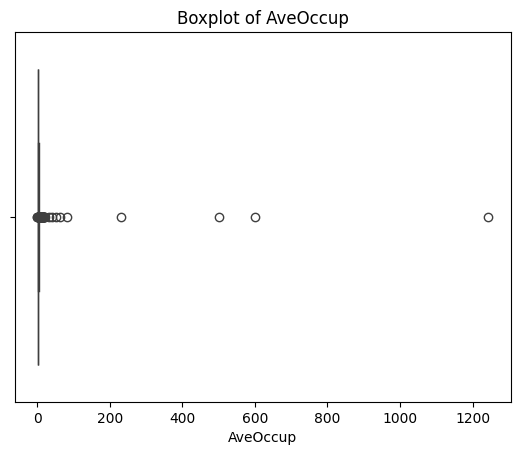

Number of outliers : 711
Before Outlier Removal : 
         AveOccup
count  20640.0000
mean       0.0000
std        1.0000
min       -0.2290
25%       -0.0617
50%       -0.0243
75%        0.0204
max      119.4191
Orginal Shape : (20640, 8)
New Shape : (19929, 8)
After Outlier Removal : 
         AveOccup
count  19929.0000
mean       0.0000
std        1.0000
min       -2.6812
25%       -0.6787
50%       -0.0775
75%        0.6059
max        2.7433


In [60]:
# Your code here: outlier detection and scaling comparison

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# df['AveOccup'].info()

sns.boxplot(data = df, x=df['AveOccup'])
plt.title('Boxplot of AveOccup')

plt.show()

Q1 = df['AveOccup'].quantile(0.25)
Q3 = df['AveOccup'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[ (df['AveOccup'] < lower) | (df['AveOccup'] > upper) ]

print(f'Number of outliers : {len(outliers)}')

# Applying Standard Scaler Before Outlier Removal

ss = StandardScaler()

ss.fit(df[['AveOccup']])

standard_before = pd.DataFrame( ss.transform(df[['AveOccup']]), columns=['AveOccup'] )

print(f'Before Outlier Removal : \n{round(standard_before.describe(), 4)}')


# Applying Standard Scaler After Outlier Removal

df_clean = df[ ( df['AveOccup'] >= lower ) & ( df['AveOccup'] <= upper ) ]

print(f'Orginal Shape : {df.shape}')
print(f'New Shape : {df_clean.shape}')

ss.fit(df_clean[['AveOccup']])

standard_after = pd.DataFrame( ss.transform(df_clean[['AveOccup']]), columns=['AveOccup'] )

print(f'After Outlier Removal : \n{round(standard_after.describe(), 4)}')


The AveOccup column contains several extreme outliers. After removing them using the IQR method, the scaled data becomes more balanced. Although StandardScaler still produces mean ≈ 0 and std ≈ 1 in both cases, the minimum and maximum scaled values become much less extreme after outlier removal. Therefore, the scaled data after outlier removal is more stable and representative of the majority of observations.

### Problem 22 ⭐
নিচের scenario-তে কোন scaler ব্যবহার করবে এবং কেন — code দিয়ে prove করো:

- Scenario A: Diabetes dataset-এর 'bmi' — normally distributed, কোনো extreme outlier নেই
- Scenario B: California Housing-এর 'AveOccup' — heavily skewed, extreme outliers আছে
- Scenario C: Wine dataset-এর 'alcohol' — neural network-এ input দেওয়া হবে

প্রতিটিতে correct scaler apply করো এবং output plot করো।

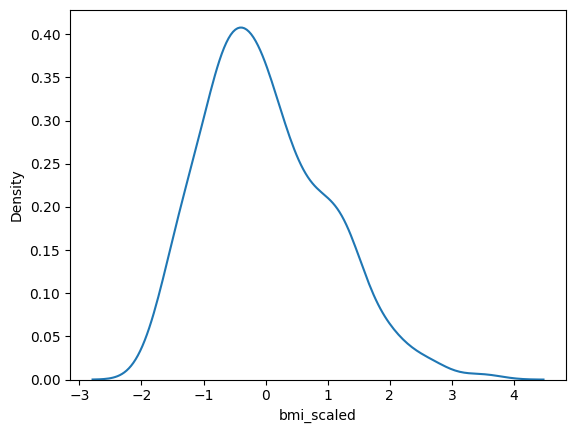

In [69]:
# Your code here: choose correct scaler for each scenario

# A

diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# We know if a columns contains not extreme outliers and normally distributed, then Standard Scaler is better

ss = StandardScaler()

ss.fit(df[['bmi']])

df['bmi_scaled'] = ss.transform(df[['bmi']])

sns.kdeplot(data = df, x = df['bmi_scaled'])
plt.show()


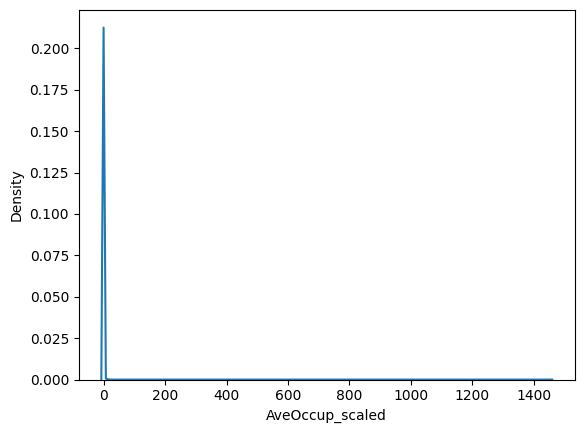

In [70]:
# B

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# For "AveOccup" we will use Robust Scaler, because it is  heavily skewed and contains extreme outliers

rs = RobustScaler()

rs.fit(df[['AveOccup']])

df['AveOccup_scaled'] = rs.transform( df[['AveOccup']] )

sns.kdeplot(data = df, x = df['AveOccup_scaled'])
plt.show()


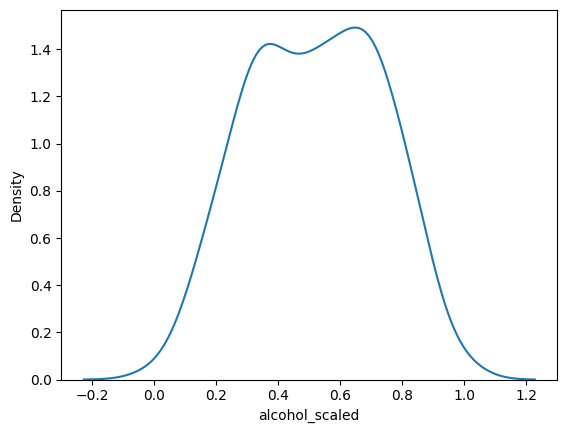

In [80]:
# C

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# df['alcohol'].sample(10)

# For "alcohol" we use MinMaxScaler, because it is used as input for a neural network and needs 0–1 scaling

mms = MinMaxScaler()

mms.fit(df[['alcohol']])

df['alcohol_scaled'] = mms.transform(df[['alcohol']])

sns.kdeplot( data = df, x = df['alcohol_scaled'] )
plt.show()

### Problem 23 ⭐
California Housing dataset-এ একটি complete ColumnTransformer pipeline তৈরি করো:
- 'MedInc' → StandardScaler (normally distributed income)
- 'Latitude', 'Longitude' → MinMaxScaler (geographic coordinates for neural net)
- 'AveOccup', 'AveRooms' → RobustScaler (skewed with outliers)
- বাকি columns → passthrough

Train-test split করে properly fit ও transform করো।
Final X_train এবং X_test shape print করো।

In [94]:
# Your code here: complete ColumnTransformer pipeline

from sklearn.impute import SimpleImputer

housing = fetch_california_housing(as_frame=True)
df = pd.DataFrame(housing.data, columns=housing.feature_names)

# df.info()

X = housing.data
y = housing.target

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

imputer_transformer = ColumnTransformer(
    transformers = [
        ( 'ss', StandardScaler(), ['MedInc'] ),
        ( 'mms', MinMaxScaler(), ['Latitude', 'Longitude'] ),
        ( 'rs', RobustScaler(), ['AveOccup', 'AveRooms'] )
    ],
    remainder='passthrough',
    verbose_feature_names_out = False
)

imputer_transformer.set_output(transform = 'pandas')

imputer_transformer.fit(X_train)

X_train = imputer_transformer.transform(X_train)
X_test = imputer_transformer.transform(X_test)

print(f'Final X_train Shape : {X_train.shape} and Final X_test Shape : {X_test.shape} ')

Final X_train Shape : (16512, 8) and Final X_test Shape : (4128, 8) 


### Problem 24 ⭐
Scaler-এর inverse_transform কী কাজ করে?
Wine dataset-এ StandardScaler apply করো।
এরপর inverse_transform দিয়ে original values ফিরিয়ে আনো।
Original এবং recovered values কি same? Verify করো।

In [103]:
# Your code here: apply StandardScaler and then inverse_transform

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)

ss = StandardScaler()

ss.fit(df)

scaled = ss.transform(df)

scaled_df = pd.DataFrame(scaled, columns = df.columns)

scaled_df

recovered = ss.inverse_transform(scaled)

recovered_df = pd.DataFrame(recovered, columns = df.columns)

recovered_df

print("Original:")
print(df.head())

print("\nRecovered:")
print(recovered_df.head())

# Check difference
diff = (df - recovered_df).abs().mean()

print("\nMean absolute difference per column:")
print(round(diff, 4))

Original:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0        

### Problem 25 ⭐
Final challenge: Data leakage এর real impact দেখাও।

Diabetes dataset-এ:
- Case A (Correct): train-এ fit, test-এ transform
- Case B (Wrong): full data-তে fit, তারপর split

দুই case-এ test set-এর scaled values-এর mean ও std compare করো।
পার্থক্য কতটুকু? Real-world-এ এই পার্থক্য কেন সমস্যা তৈরি করে সেটা comment-এ লেখো।

In [110]:
# Your code here: demonstrate real impact of data leakage

diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

# A

scaler_a = StandardScaler()

scaler_a.fit(X_train)
X_test_a = scaler_a.transform(X_test)

X_test_a = pd.DataFrame(X_test_a, columns=X.columns)

mean_a = X_test_a.mean()
std_a = X_test_a.std()

# B

scaler_b = StandardScaler()

scaler_b.fit(X)   # leakage

X_scaled = scaler_b.transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# split AFTER scaling (wrong way)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

mean_b = X_test_b.mean()
std_b = X_test_b.std()


print("\nAverage Mean Difference:", abs(mean_a - mean_b).mean())
print("Average Std Difference:", abs(std_a - std_b).mean())


Average Mean Difference: 0.021898986812485838
Average Std Difference: 0.00926512672787555


## Real-world impact of Data Leakage

If we fit the scaler using the full dataset (including the test set), the model indirectly learns information from the test data. This causes **data leakage**.

In real-world deployment, new unseen data does not follow this leaked distribution. As a result:

- The model shows **overly optimistic performance during testing**
- But performs **poorly on real-world data**
- The evaluation becomes **unreliable and misleading**

Therefore, preprocessing steps must always be fitted only on the training data, not on the full dataset.